# Reaction Rate Fields and Reactors

CHBE444: Design I, Prof. Ganesh Sriram (gsriram@umd.edu), University of Maryland.

## 0. Introduction

This script plots the reaction rate field for the familiar system A $\rightarrow$ B $\rightarrow$ C with first-order kinetics. This system was introduced in previous courses and HW 1, and analyzed further in lectures F.01 and F.02 of Module F.

The kinetics of the reactions are as follows:

|Reaction|Rate expression|Units|
|:------:|:-------------:|:----|
|$r_1$   | $k_1 C_A$     |$M/s$|
|$r_2$   | $k_2 C_B$     |$M/s$|

Due to the stoichiometry, the rates of formation of A and B are given by:

$$r_A = - k_1 C_A$$
$$r_B = k_1 C_A - k_2 C_B$$

Let us use the same rate constants we used in previous assignments involving this reaction system: $k_1 = 3 \ s^{-1}$, $k_2 = 2 \ s^{-1}$. 

## 1. Specify the Reaction System and Plot a Rate Field

### 1.1 Specify the reaction system

+ Let us define an reaction system object containing the component and reaction data, and give it the name `sysABC`.
+ In this package, reaction systems are objects in the class `ReactionSystem`.
+ If you need detailed help with the `ReactionSystem` class, run the following after `chbe444umd` has been imported as `des`:
  >`des.ReactionSystem?`
+ This will show you an example and descriptions of the arguments.

In [1]:
import chbe444umd as des

sysABC = des.ReactionSystem(
    component_ids=('A', 'B', 'C'),
    component_names={'A': 'A', 'B': 'B', 'C': 'C'},
    axes={'A': 0, 'B': 1},
    h_lim=[0, 1],
    v_lim=[0, 1],
    reactions=('r1', 'r2'),
    stoich={'r1': {'A': -1, 'B': 1},
            'r2': {'B': -1, 'C': 1}},
    kinetics={'r1': lambda C: 3 * C['A'],
              'r2': lambda C: 2 * C['B']},
)

### 1.2 Examine input

 + No output appears after you run the previous cell. However, you can examine your input by running:
  >`sysABC`



### 1.3 Perform a sanity check to see if reaction rates are calculated correctly

+ The method `sysABC.rate(x)` gives the rates of formation of the axis components (in this case, $r_A$ and $r_B$) at a point in the concentration space denoted by the vector `x`.
+ As per the reaction stoichiometry:

$$r_A = -r_1$$
$$r_B = r_1 - r_2$$

+ Let us see if we get the correct rates corresponding to $C_A = 0.6 \ M$, $C_B = 0.4 \ M$.
+ We need to enter concentrations in the sequence the axis components are specified in `axes=` argument above. Thus, $C_A$ should be entered first (position 0) and $C_B$ should be entered next (position 1). Hence, the input `x` is `[0.6, 0.4]`.
+ The output should be $r_A = -1.8 \ M/s$, $r_B = 1.0 \ M/s$. Verify these numbers by calculating them yourself.

In [2]:
sysABC.rate([0.6, 0.4])

array([-1.8,  1. ])

### 1.4 Plot a rate field

+ The following two "magic" commands (with the % sign) will render figures as scalable vector graphics (svg) format.
+ This will keep the figures sharp, without looking pixelated when zoomed in.
+ You just need to run them once in any Jupyter notebook in which you have graphics.

In [3]:
%config InlineBackend.figure_format='svg'
%matplotlib inline

+ The following command calls the method `plot_rate_field` on the `sysABC` object.
+ You can also run variations of the method like this:
>`sysABC.plot_rate_field()`  # simplest form with default options  
>`fig, ax, _ = sysABC.plot_rate_field(fsize=6, n_vec=41, arrow_scale=41)`
+ It is best to make the function return `fig` and `ax`, as we will need them for subsequent methods.

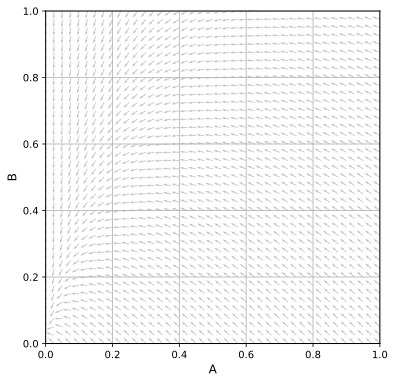

In [4]:
fig, ax, quiver = sysABC.plot_rate_field(fsize=6, n_vec=41, arrow_scale=41)

## 2. Specify and Simulate Reactors

### ✎ Exercise

<font color="blue">
Design a reactor config consisting of a CSTR (first) and a PFR (next) in series, whose final product has $\bar{C}_A$ = 0.20 and $\bar{C}_B$ = 0.35. The CSTR effluent should have an A conversion of 60%.
</font>

### 2.1 Specify and Simulate a PFR and a CSTR

+ Reactors are instances of the `Reactor` class.
+ To get help with this class, run the following after `chbe444umd` has been imported as `des`:
  >`des.Reactor?`
+ Reactors are simulated by the `.simulate` method.
+ To get help with this method, run the following after `chbe444umd` has been imported as `des`:
  >`des.Reactor.simulate?`  
+ Or run the following after `pfr1` is specified:
  >`pfr1.simulate?`
+ Let us specify and simulate the following reactors:
  + PFR with fresh feed at $[1, 0]$,
  + CSTR with fresh feed at $[1, 0]$.
+ We can specify an integration or calculation time via the parameter `time` in the reactor specification or the parameter `time_limit` in the `.simulate` method.

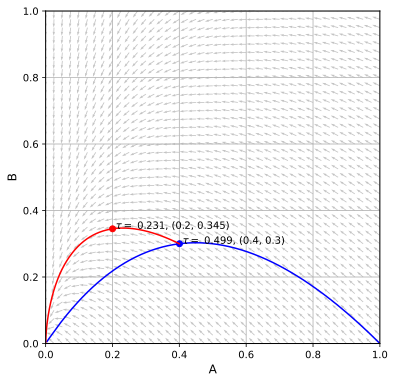

In [5]:
fig1, ax1 = des.duplicate_figure(fig)  # plot on a duplicate of original figure

cstr1 = des.Reactor(name='CSTR1', flow_type='cstr', feed=[1, 0])
cstr1.simulate(system=sysABC, ax=ax1, time_limit=100)
cstr1.plot_point(ax1, x=0.4)  # x-coordinate (CA) = 0.4

pfr1 = des.Reactor(name='PFR1', flow_type='pfr', feed=[0.4, 0.3], time=10)
pfr1.simulate(system=sysABC, ax=ax1)
pfr1.plot_point(ax1, x=0.20)

fig1  # you may need to run this line to get the updated figure to display